In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
image = cv2.imread('img.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

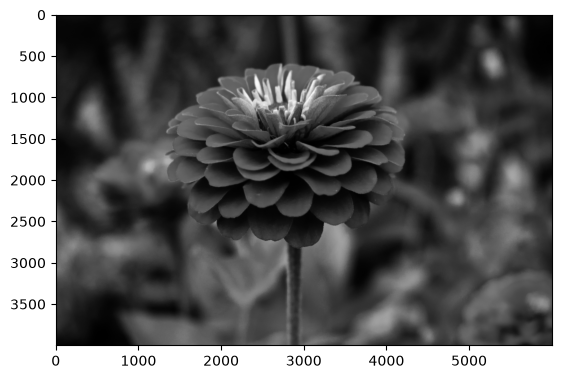

In [3]:
plt.imshow(image_gray, cmap="gray")

In [4]:
mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

array([[  0,  16,   0, ..., 150,  56,   0],
       [ 86,   0, 238, ...,   0,   0,  36],
       [ 39, 106,   0, ...,   0, 194,   0],
       ...,
       [  0,   0,  36, ...,   0,  35, 139],
       [  0,   0,   0, ...,   0, 106,   0],
       [102,   0,   0, ...,   0,  67,   0]],
      shape=(4000, 6000), dtype=uint8)

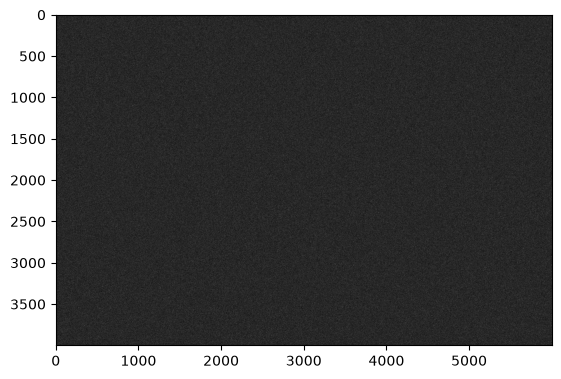

In [5]:
plt.imshow(noise_gauss, cmap="gray")

In [6]:
image_noise_gauss = cv2.add(image_gray,noise_gauss)

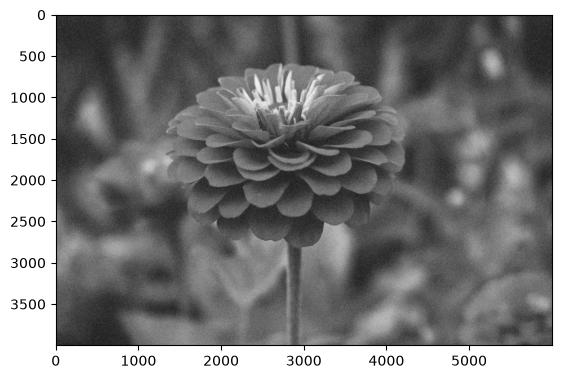

In [7]:
plt.imshow(image_noise_gauss, cmap="gray")

In [14]:
from skimage.metrics import structural_similarity, mean_squared_error
mse_gauss = mean_squared_error(image_gray, image_noise_gauss)
(ssim, diff) = structural_similarity(image_gray, image_noise_gauss, full=True)
print(mse_gauss, ssim)

4498.495616958333 0.025890101157439005


In [15]:
image_gauss_median = cv2.medianBlur(image_noise_gauss, 3)

In [16]:
mse_gauss_median = mean_squared_error(image_gray, image_gauss_median)
(ssim_gauss_median, diff) = structural_similarity(image_gray,  image_gauss_median, full=True)

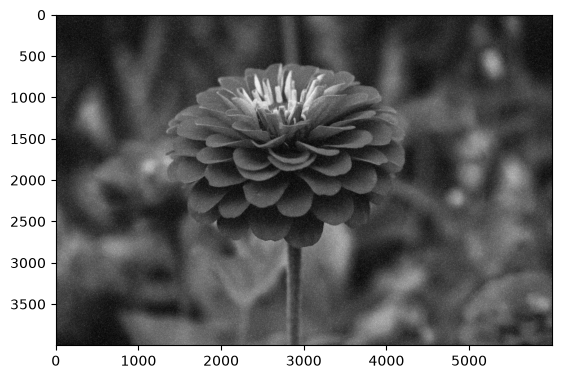

In [18]:
plt.imshow(image_gauss_median, cmap="gray")

In [17]:
print(mse_gauss_median, ssim_gauss_median)

844.0684315833333 0.1536194148874991


In [32]:
image_gauss_gauss = cv2.GaussianBlur(image_noise_gauss, (5, 5), 0)

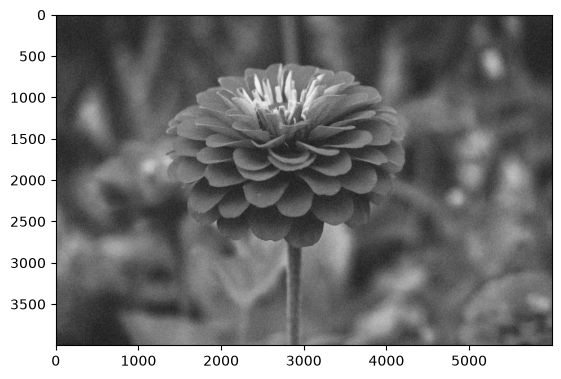

In [33]:
plt.imshow(image_gauss_gauss, cmap="gray")

In [34]:
mse_gauss_gauss = mean_squared_error(image_gray, image_gauss_gauss)
(ssim_gauss_gauss, diff) = structural_similarity(image_gray, image_gauss_gauss, full=True)
print(mse_gauss_gauss, ssim_gauss_gauss)

1729.2054128333334 0.2304045520784348


In [35]:
image_gauss_bilat = cv2.bilateralFilter(image_noise_gauss, 9, 75, 75)

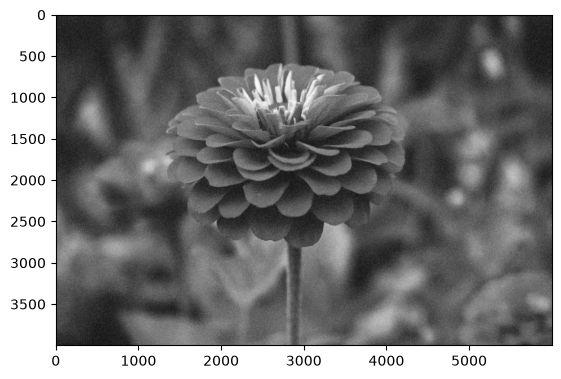

In [36]:
plt.imshow(image_gauss_bilat, cmap="gray")

In [37]:
mse_gauss_bilat = mean_squared_error(image_gray, image_gauss_bilat)
(ssim_gauss_bilat, diff) = structural_similarity(image_gray, image_gauss_bilat, full=True)
print(mse_gauss_bilat, ssim_gauss_bilat)

1786.3903612083334 0.1045069515651392


In [38]:
image_gauss_nlm = cv2.fastNlMeansDenoising(image_noise_gauss, h=20)

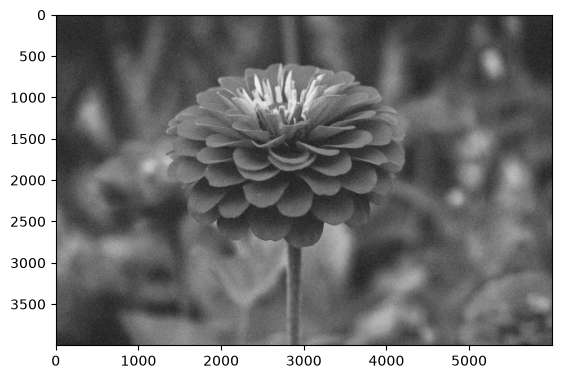

In [39]:
plt.imshow(image_gauss_nlm, cmap="gray")

In [40]:
mse_gauss_nlm = mean_squared_error(image_gray, image_gauss_nlm)
(ssim_gauss_nlm, diff) = structural_similarity(image_gray, image_gauss_nlm, full=True)
print(mse_gauss_nlm, ssim_gauss_nlm)

4486.269640875 0.028931002176420983


In [ ]:
# ДЛЯ КАРТИНКИ, ЗАШУМЛЕННОЙ С ПОМОЩЬЮ ШУМА ГАУСА, ЛУЧШИЙ MSE ПОКАЗЫВАЕТ МЕДИАННАЯ ФИЛЬТРАЦИЯ, А ЛУЧШИЙ SSIM ФИЛЬТР ГАУССА

In [8]:
noise =  np.random.randint(0, 101, size = (image_gray.shape[0], image_gray.shape[1]), dtype=int)
zeros_pixel = np.where(noise == 0)
ones_pixel = np.where(noise == 100)

In [9]:
bg_image = np.ones(image_gray.shape, np.uint8) * 128

In [10]:
bg_image[zeros_pixel] = 0
bg_image[ones_pixel] = 255

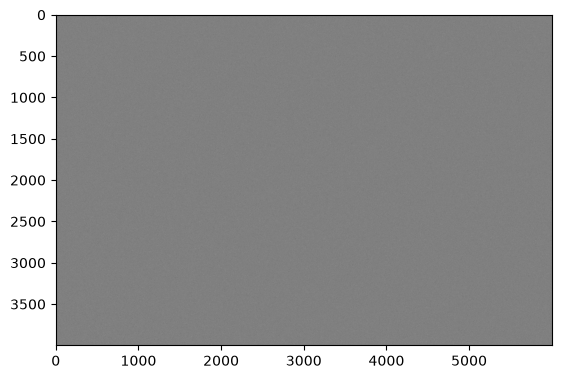

In [11]:
plt.imshow(bg_image, cmap="gray")

In [12]:
import copy

image_sp = copy.deepcopy(image_gray)

image_sp[zeros_pixel] = 0
image_sp[ones_pixel] = 255

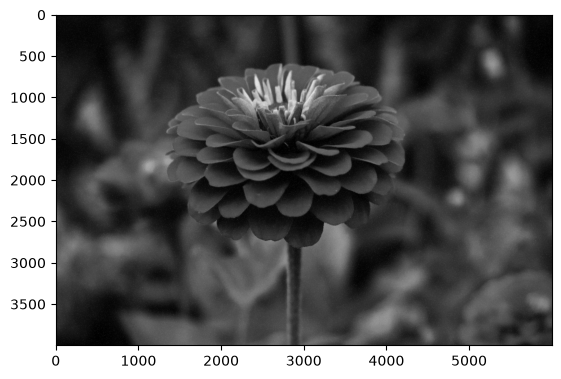

In [13]:
plt.imshow(image_sp, cmap="gray")

In [19]:
mse_sp = mean_squared_error(image_gray, image_sp)
(ssim_sp, diff) = structural_similarity(image_gray, image_sp, full=True)
print(mse_sp, ssim_sp)

444.395467125 0.5501159516843893


In [20]:
image_sp_median = cv2.medianBlur(image_sp, 3)

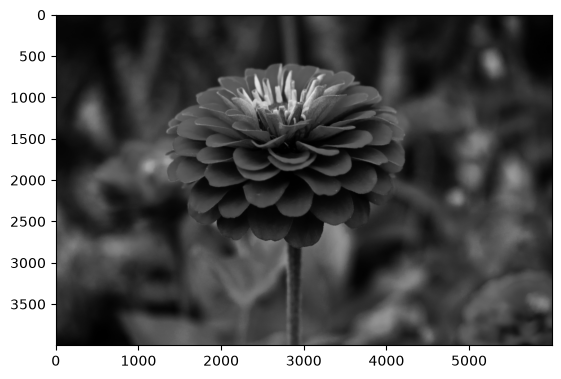

In [22]:
plt.imshow(image_sp_median, cmap="gray")

In [21]:
mse_sp_median = mean_squared_error(image_gray, image_sp_median)
(ssim_sp_median, diff) = structural_similarity(image_gray, image_sp_median, full=True)
print(mse_sp_median, ssim_sp_median)

7.718579041666667 0.9115585210056601


In [23]:
image_sp_gauss = cv2.GaussianBlur(image_sp, (5, 5), 0)

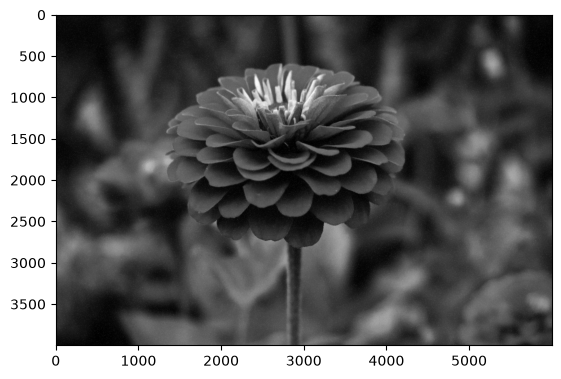

In [24]:
plt.imshow(image_sp_gauss, cmap="gray")

In [25]:
mse_sp_gauss = mean_squared_error(image_gray, image_sp_gauss)
(ssim_sp_gauss, diff) = structural_similarity(image_gray, image_sp_gauss, full=True)
print(mse_sp_gauss, ssim_sp_gauss)

43.250506666666666 0.7129602525233709


In [26]:
image_sp_bilat = cv2.bilateralFilter(image_sp, 9, 75, 75)

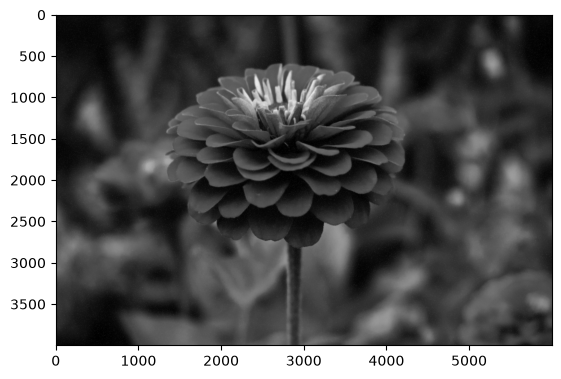

In [27]:
plt.imshow(image_sp_bilat, cmap="gray")

In [28]:
mse_sp_bilat = mean_squared_error(image_gray, image_sp_bilat)
(ssim_sp_bilat, diff) = structural_similarity(image_gray, image_sp_bilat, full=True)
print(mse_sp_bilat, ssim_sp_bilat)

171.021739125 0.6298863106964825


In [29]:
image_sp_nlm = cv2.fastNlMeansDenoising(image_sp, h=20)

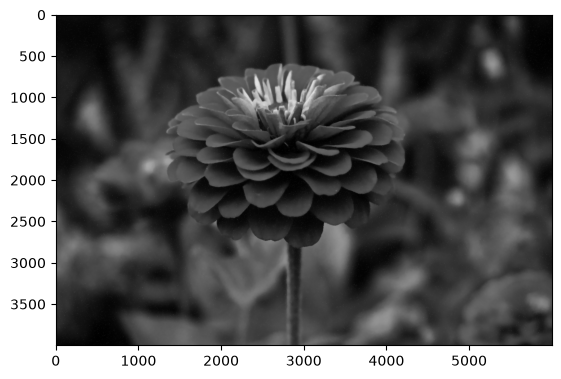

In [30]:
plt.imshow(image_sp_nlm, cmap="gray")

In [31]:
mse_sp_nlm = mean_squared_error(image_gray, image_sp_nlm)
(ssim_sp_nlm, diff) = structural_similarity(image_gray, image_sp_nlm, full=True)
print(mse_sp_nlm, ssim_sp_nlm)

63.95239370833333 0.7511645054995538


In [ ]:
# ДЛЯ КАРТИНКИ, ЗАШУМЛЕННОЙ С ПОМОЩЬЮ ПОСТОЯННОГО ШУМА, ЛУЧШЕЙ ФИЛЬТРАЦИЕЙ ЯВЛЯЕТСЯ МЕДИАННАЯ